In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_path="/content/drive/MyDrive/StudentsPerformance.csv"

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [5]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [6]:
print("Shape of dataset:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Shape of dataset: (1000, 8)

Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Missing Values:
gende

In [7]:
print("Shape of dataset:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Shape of dataset: (1000, 8)

Column Names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB

Missing Values:
gende

In [8]:
df.columns = df.columns.str.strip().str.lower()

df.columns = df.columns.str.replace(' ', '_')

print(df.columns)

Index(['gender', 'race/ethnicity', 'parental_level_of_education', 'lunch',
       'test_preparation_course', 'math_score', 'reading_score',
       'writing_score'],
      dtype='object')


In [9]:
avg_scores = df.groupby(
    ['parental_level_of_education', 'lunch']
)[['math_score', 'reading_score', 'writing_score']].mean()

print(avg_scores)

                                          math_score  reading_score  \
parental_level_of_education lunch                                     
associate's degree          free/reduced   62.610390      67.649351   
                            standard       70.682759      72.668966   
bachelor's degree           free/reduced   63.000000      68.931818   
                            standard       73.189189      75.418919   
high school                 free/reduced   54.514286      60.214286   
                            standard       66.373016      67.198413   
master's degree             free/reduced   61.166667      70.291667   
                            standard       75.628571      78.857143   
some college                free/reduced   60.126582      65.075949   
                            standard       70.891156      71.816327   
some high school            free/reduced   53.934426      60.114754   
                            standard       68.440678      70.466102   

     

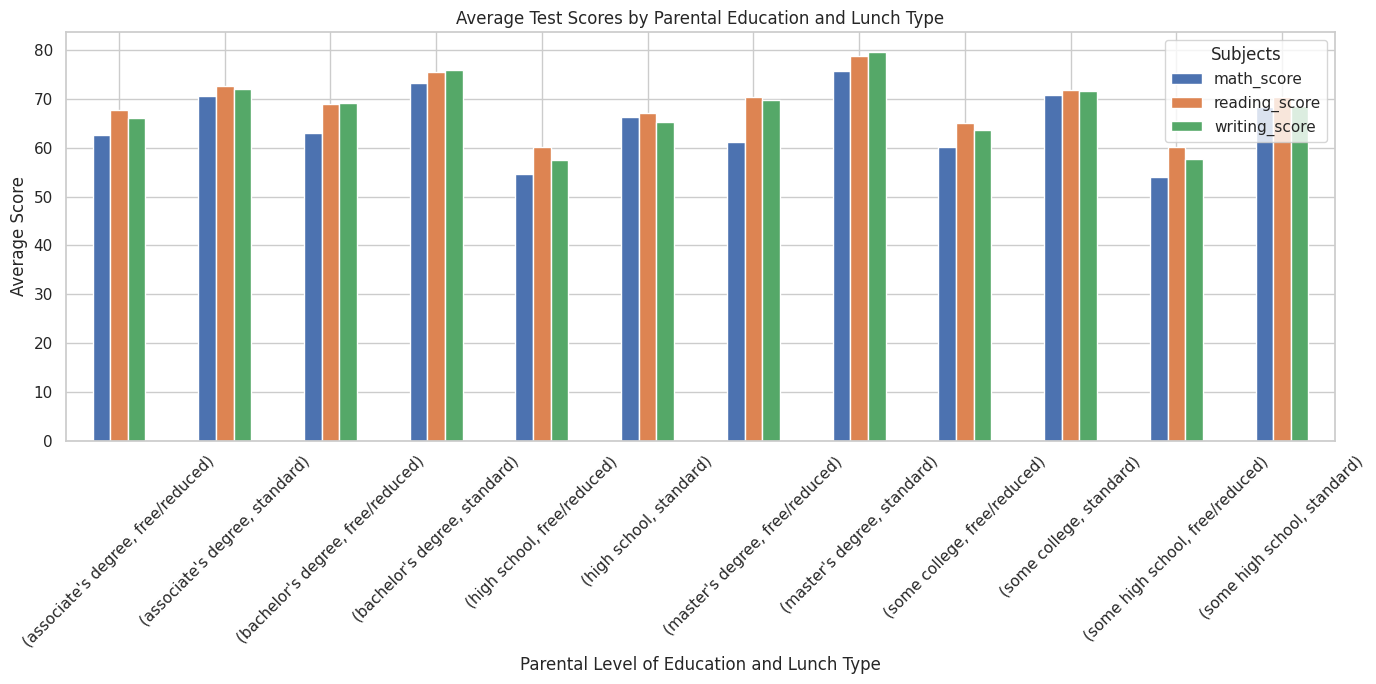

In [10]:
avg_scores.plot(
    kind='bar',
    figsize=(14, 7)
)

plt.title('Average Test Scores by Parental Education and Lunch Type')
plt.xlabel('Parental Level of Education and Lunch Type')
plt.ylabel('Average Score')
plt.xticks(rotation=45)
plt.legend(title='Subjects')
plt.tight_layout()
plt.show()

In [11]:
df['average_score'] = df[
    ['math_score', 'reading_score', 'writing_score']
].mean(axis=1)

print(df[['test_preparation_course', 'average_score']].head())

  test_preparation_course  average_score
0                    none      72.666667
1               completed      82.333333
2                    none      92.666667
3                    none      49.333333
4                    none      76.333333


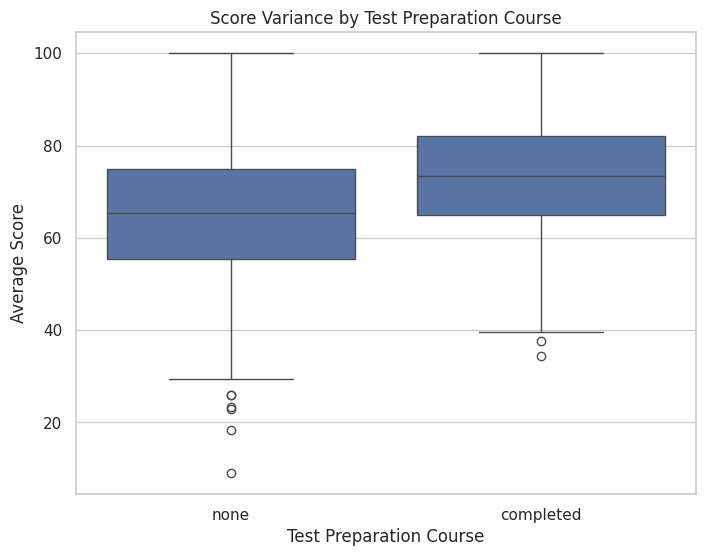

In [12]:
plt.figure(figsize=(8, 6))

sns.boxplot(
    x='test_preparation_course',
    y='average_score',
    data=df
)

plt.title('Score Variance by Test Preparation Course')
plt.xlabel('Test Preparation Course')
plt.ylabel('Average Score')

plt.show()

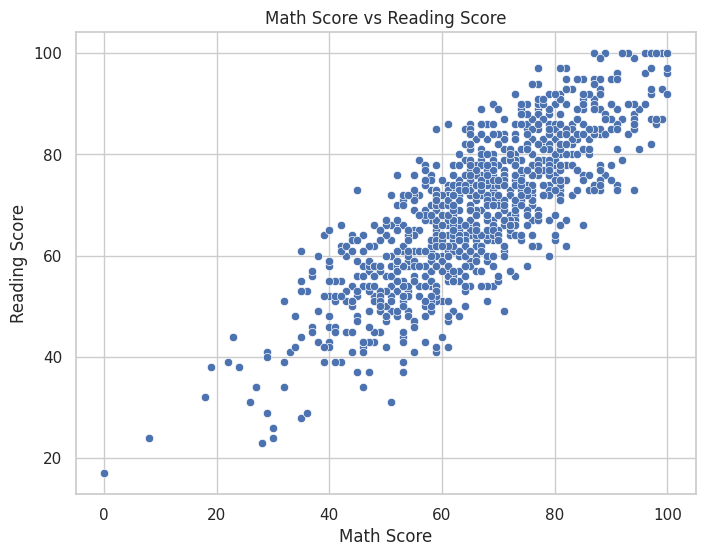

In [13]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x='math_score',
    y='reading_score',
    data=df
)

plt.title('Math Score vs Reading Score')
plt.xlabel('Math Score')
plt.ylabel('Reading Score')

plt.show()

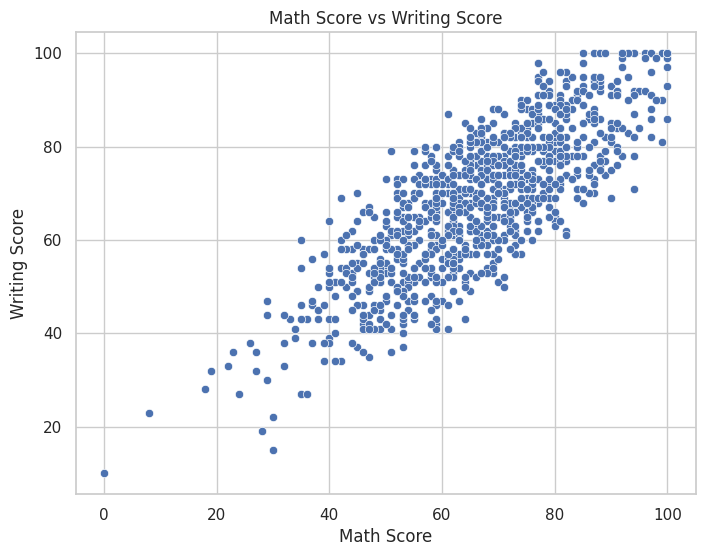

In [14]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x='math_score',
    y='writing_score',
    data=df
)

plt.title('Math Score vs Writing Score')
plt.xlabel('Math Score')
plt.ylabel('Writing Score')

plt.show()

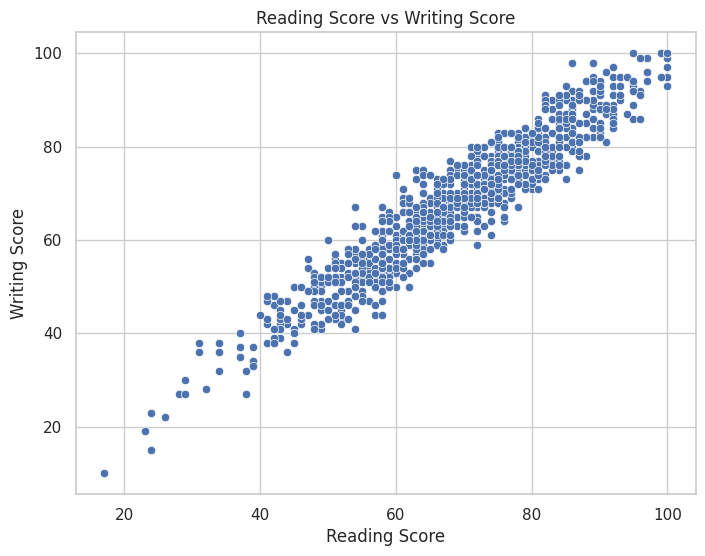

In [15]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x='reading_score',
    y='writing_score',
    data=df
)

plt.title('Reading Score vs Writing Score')
plt.xlabel('Reading Score')
plt.ylabel('Writing Score')

plt.show()

In [16]:
score_columns = [
    'math_score',
    'reading_score',
    'writing_score'
]

correlation = df[score_columns].corr()

print(correlation)

               math_score  reading_score  writing_score
math_score       1.000000       0.817580       0.802642
reading_score    0.817580       1.000000       0.954598
writing_score    0.802642       0.954598       1.000000


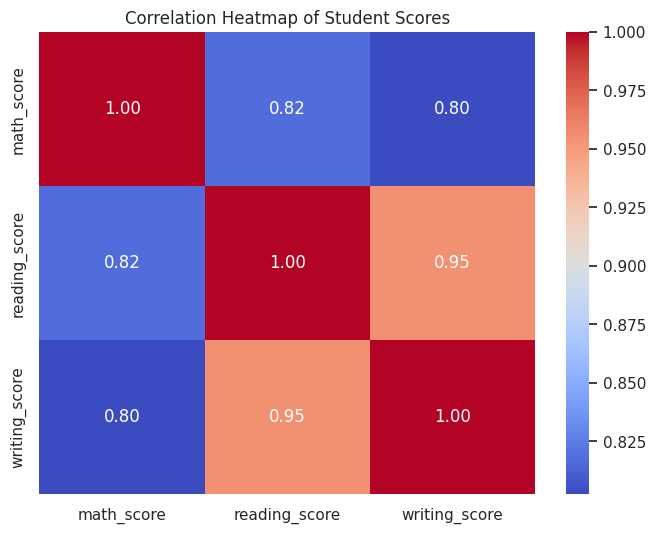

In [17]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Student Scores')

plt.show()

In [18]:
print("Subject-to-Subject Correlations:\n")

print("Math and Reading:",
      df['math_score'].corr(df['reading_score']))

print("Math and Writing:",
      df['math_score'].corr(df['writing_score']))

print("Reading and Writing:",
      df['reading_score'].corr(df['writing_score']))


Subject-to-Subject Correlations:

Math and Reading: 0.8175796636720546
Math and Writing: 0.8026420459498085
Reading and Writing: 0.9545980771462476


In [19]:
corr_matrix = df[score_columns].corr()

pairs = []

for i in range(len(score_columns)):
    for j in range(i + 1, len(score_columns)):
        pairs.append(
            (
                score_columns[i],
                score_columns[j],
                corr_matrix.iloc[i, j]
            )
        )

pairs = sorted(pairs, key=lambda x: abs(x[2]), reverse=True)

print("Strongest Subject Correlation:")
print(pairs[0])

Strongest Subject Correlation:
('reading_score', 'writing_score', np.float64(0.9545980771462476))


In [20]:
prep_comparison = df.groupby(
    'test_preparation_course'
)[['math_score', 'reading_score', 'writing_score']].mean()

print(prep_comparison)

                         math_score  reading_score  writing_score
test_preparation_course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673


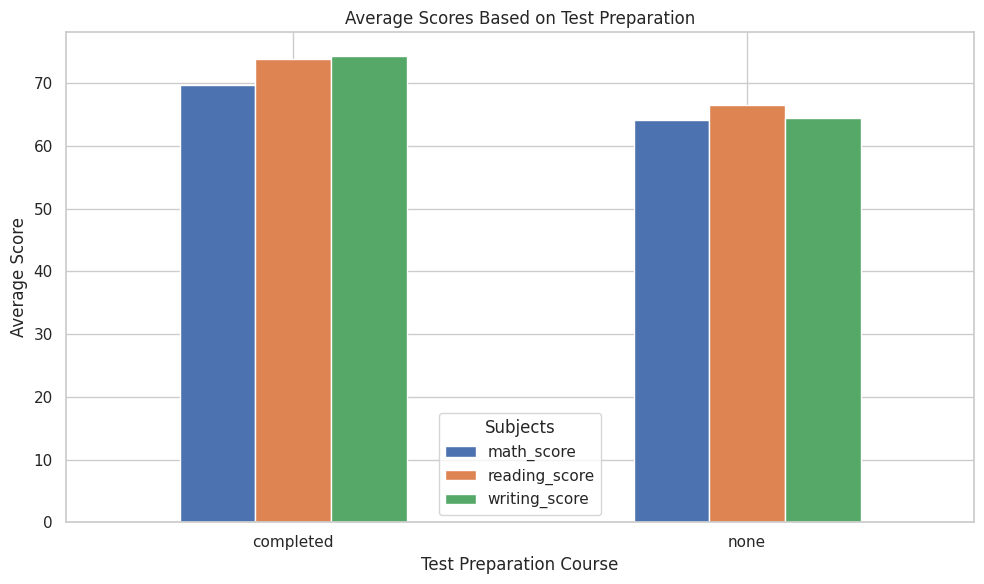

In [21]:
prep_comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Scores Based on Test Preparation')
plt.xlabel('Test Preparation Course')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Subjects')

plt.tight_layout()
plt.show()

In [22]:
parental_scores = df.groupby(
    'parental_level_of_education'
)[['math_score', 'reading_score', 'writing_score']].mean()

print(parental_scores)

                             math_score  reading_score  writing_score
parental_level_of_education                                          
associate's degree            67.882883      70.927928      69.896396
bachelor's degree             69.389831      73.000000      73.381356
high school                   62.137755      64.704082      62.448980
master's degree               69.745763      75.372881      75.677966
some college                  67.128319      69.460177      68.840708
some high school              63.497207      66.938547      64.888268


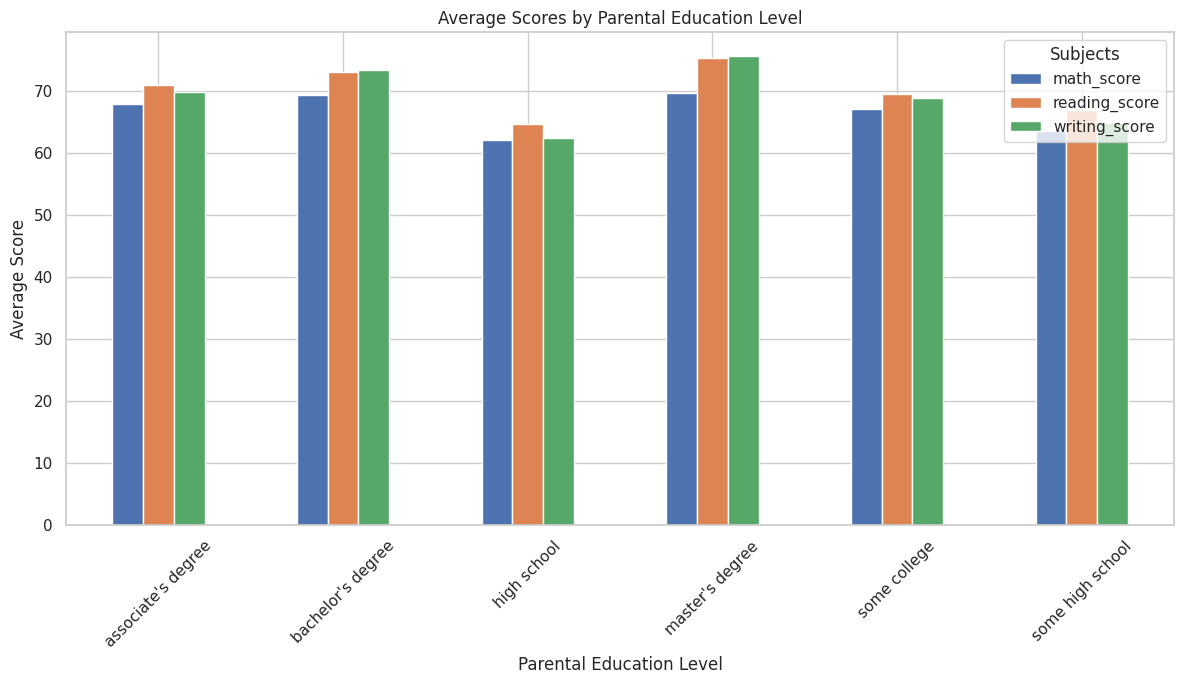

In [23]:
parental_scores.plot(
    kind='bar',
    figsize=(12, 7)
)

plt.title('Average Scores by Parental Education Level')
plt.xlabel('Parental Education Level')
plt.ylabel('Average Score')
plt.xticks(rotation=45)
plt.legend(title='Subjects')

plt.tight_layout()
plt.show()

In [24]:
lunch_scores = df.groupby(
    'lunch'
)[['math_score', 'reading_score', 'writing_score']].mean()

print(lunch_scores)

              math_score  reading_score  writing_score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256


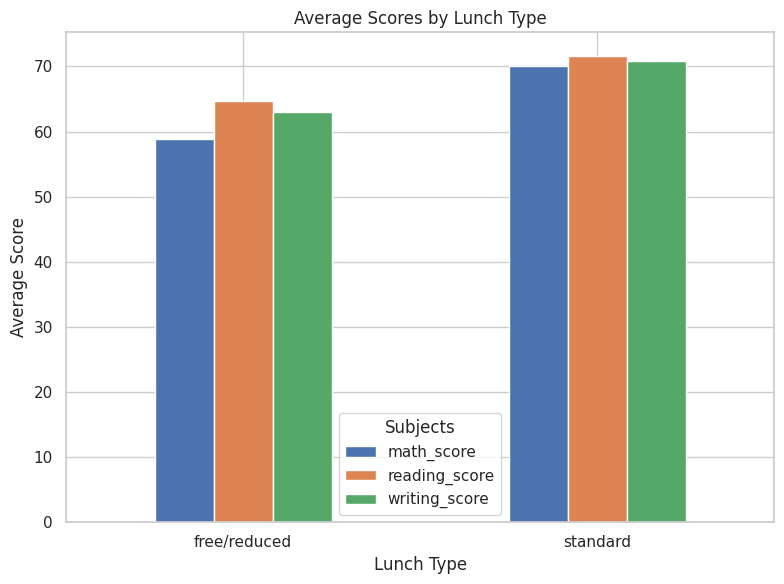

In [25]:
lunch_scores.plot(
    kind='bar',
    figsize=(8, 6)
)

plt.title('Average Scores by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Subjects')

plt.tight_layout()
plt.show()

In [26]:
print("========== FINAL FINDINGS ==========")

print("\n1. Subject Correlations:")
print(correlation)

print("\n2. Average Scores by Test Preparation:")
print(prep_comparison)

print("\n3. Average Scores by Lunch Type:")
print(lunch_scores)

print("\n4. Average Scores by Parental Education:")
print(parental_scores)

========== FINAL FINDINGS ==========

1. Subject Correlations:
               math_score  reading_score  writing_score
math_score       1.000000       0.817580       0.802642
reading_score    0.817580       1.000000       0.954598
writing_score    0.802642       0.954598       1.000000

2. Average Scores by Test Preparation:
                         math_score  reading_score  writing_score
test_preparation_course                                          
completed                 69.695531      73.893855      74.418994
none                      64.077882      66.534268      64.504673

3. Average Scores by Lunch Type:
              math_score  reading_score  writing_score
lunch                                                 
free/reduced   58.921127      64.653521      63.022535
standard       70.034109      71.654264      70.823256

4. Average Scores by Parental Education:
                             math_score  reading_score  writing_score
parental_level_of_education                